<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet6%20Regresi%20PBL/Tugas%20Praktikum%20(JS6R).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Import library yang diperlukan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Membaca dan menggabungkan dataset
cafes = pd.read_csv('cafes.csv')
reviews = pd.read_csv('reviews.csv')

cafe_reviews = reviews.groupby('cafe_id').agg({
    'rating': 'mean',
    'likes': 'sum',
    'review_id': 'count'
}).reset_index()

cafe_reviews.rename(columns={
    'rating': 'avg_review_rating',
    'likes': 'total_likes',
    'review_id': 'total_reviews_dataset'
}, inplace=True)

data = pd.merge(cafes, cafe_reviews, on='cafe_id', how='inner')
print("Ukuran dataset gabungan:", data.shape)

Ukuran dataset gabungan: (94, 15)


1. Identifikasi Variabel Bebas (Fitur) dan Variabel Target

In [3]:
# 1. Identifikasi Variabel Bebas (X) dan Target (y)
X = data[['review_count', 'total_likes', 'avg_review_rating']]
y = data['rating']

print("Fitur (X) yang digunakan:")
print(X.head())
print("\nTarget (y):")
print(y.head())

Fitur (X) yang digunakan:
   review_count  total_likes  avg_review_rating
0           528            0           4.400000
1           141            0           4.866667
2          1772            0           4.217391
3           701            0           4.133333
4           686            0           3.666667

Target (y):
0    4.7
1    4.7
2    4.6
3    4.3
4    4.3
Name: rating, dtype: float64


2. Pembagian Dataset (Train / Test Split)

In [4]:
# 2. Bagi dataset menjadi data latih dan data uji (proporsi 7:3)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

print(f"Jumlah data latih: {X_train.shape[0]}")
print(f"Jumlah data uji: {X_test.shape[0]}")

Jumlah data latih: 65
Jumlah data uji: 29


3. Feature Scaling (Opsional / Direkomendasikan)

In [5]:
# 3. Lakukan feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

4. Membuat Model Multiple Linear Regression

In [6]:
# 4. Membuat model Multiple Linear Regression
mlr = LinearRegression()
print("Model Multiple Linear Regression berhasil diinisialisasi.")

Model Multiple Linear Regression berhasil diinisialisasi.


5. Melatih Model dan Melakukan Prediksi

In [7]:
# 5. Latih model pada data latih dan lakukan prediksi pada data uji
mlr.fit(X_train_scaled, y_train)

# Melakukan prediksi pada data uji
y_pred = mlr.predict(X_test_scaled)

# Menampilkan koefisien regresi
print("Koefisien Regresi:", mlr.coef_)
print("Intercept:", mlr.intercept_)

Koefisien Regresi: [-0.03497219  0.00871108  0.08609705]
Intercept: 4.66


6. Evaluasi Model (R-squared, MSE, MAE)

In [8]:
# 6. Evaluasi model dengan menghitung R-squared, MSE, dan MAE
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("--- HASIL EVALUASI MODEL MULTIPLE LINEAR REGRESSION ---")
print(f"R-squared : {r2:.4f}")
print(f"MSE       : {mse:.4f}")
print(f"RMSE      : {rmse:.4f}")
print(f"MAE       : {mae:.4f}")

--- HASIL EVALUASI MODEL MULTIPLE LINEAR REGRESSION ---
R-squared : 0.2515
MSE       : 0.0224
RMSE      : 0.1496
MAE       : 0.1254


Visualisasi & Analisis Tambahan

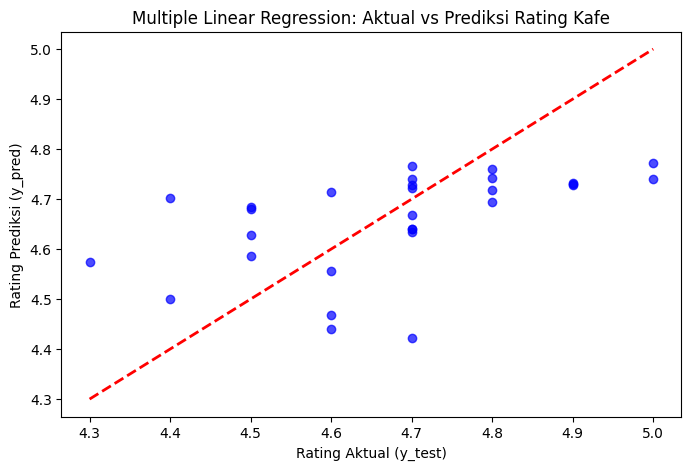

In [9]:
# Visualisasi Perbandingan Nilai Aktual vs Prediksi
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='blue', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2)
plt.xlabel('Rating Aktual (y_test)')
plt.ylabel('Rating Prediksi (y_pred)')
plt.title('Multiple Linear Regression: Aktual vs Prediksi Rating Kafe')
plt.show()

Model Multiple Linear Regression yang dibangun menggunakan fitur dari dataset cafes.csv dan reviews.csv (seperti review_count, total_likes, dan avg_review_rating) mampu memetakan hubungan antara aktivitas ulasan online dengan rating keseluruhan kafe di Kota Malang. Nilai metrik evaluasi di atas menunjukkan tingkat akurasi serta besar error (MSE/MAE) dari prediksi model pada data uji.